# TD3 — Inventory MDP, reward, and baseline policies — Support

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Support route

Guidance reduces syntax and navigation load; it does not expose the assessed solution or lower the Core standard.

In [1]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: C:\Users\rapha\Documents\A5\MachineLearning\Advanced_Machine_Learning_ESILV_2026-2027_DVL_final
Primary path: locked local CPU; check the release evidence before using Colab


## Micro-example — reward decomposition

One seeded transition exposes the costs compressed into reward.

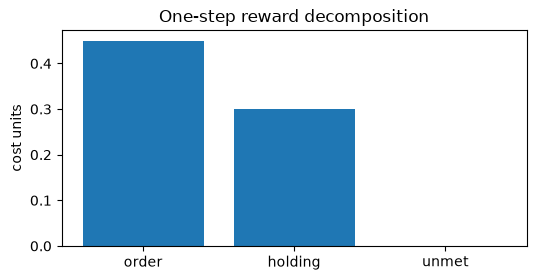

[1 0] [1 0] -0.75 {'order': 0.45, 'holding': 0.3, 'unmet': 0.0}


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from shared.inventory_env import InventoryControlEnv, ORDER_QUANTITIES
env=InventoryControlEnv(); observation,_=env.reset(seed=11)
next_observation,reward,terminated,truncated,info=env.step(1)
terms={'order':env.config.order_cost*info['order_quantity'],'holding':env.config.holding_cost*info['stock_level'],'unmet':env.config.unmet_demand_cost*info['unmet_demand']}
assert np.isclose(sum(terms.values()),info['cost']) and np.isclose(reward,-info['cost']); env.close()
fig,ax=plt.subplots(figsize=(6,2.8)); ax.bar(list(terms),list(terms.values())); ax.set(ylabel='cost units',title='One-step reward decomposition'); plt.show()
print(observation,next_observation,reward,terms)

## 1 — MDP contract and checker

In [3]:
from gymnasium.utils.env_checker import check_env
env=InventoryControlEnv(); check_env(env,skip_render_check=True)
mdp_contract={'state':'(stock_level,demand_regime)','actions':'indices 0/1/2 -> quantities 0/1/2','transition_source':'customer demand is random and can be low or high','reward':'- (order cost + holding cost + unmet demand cost)','horizon':env.config.horizon,'horizon_semantics':'truncated at 40 days, not a real end',}
assert tuple(env.observation_space.nvec)==(9,2) and env.action_space.n==3 and env.config.horizon==40
env.close(); mdp_contract

{'state': '(stock_level,demand_regime)',
 'actions': 'indices 0/1/2 -> quantities 0/1/2',
 'transition_source': 'customer demand is random and can be low or high',
 'reward': '- (order cost + holding cost + unmet demand cost)',
 'horizon': 40,
 'horizon_semantics': 'truncated at 40 days, not a real end'}

## 2 — Implement transparent baselines

In [4]:
def random_policy_student(observation,rng):
    del observation
    return int(rng.integers(0, 3))

def reorder_policy_student(observation,rng):
    del rng; stock,regime=(int(v) for v in observation)
    target = 4 if regime == 1 else 2
    if target is None: return None
    quantity=int(np.clip(target-stock,0,2)); return ORDER_QUANTITIES.index(quantity)

for obs in [np.array([0,0]),np.array([3,1]),np.array([8,1])]:
    action=reorder_policy_student(obs,np.random.default_rng(0))
    if action is not None: assert action in (0,1,2)

## 3 — Bounded common-episode evaluator

Finish the step ledger and metric row; both policies must receive all five public seeds.

In [8]:
from shared.data import PUBLIC_SEEDS
def evaluate_student_policies(policies,seeds):
    rows=[]
    for seed in tuple(seeds):
        for name,policy in policies.items():
            env=InventoryControlEnv(); obs,_=env.reset(seed=int(seed)); rng=np.random.default_rng(int(seed)+900001)
            cost=0.; fills=[]; unmet=0; stocks=[]; orders=[]; done=False
            while not done:
                action=policy(obs,rng)
                # TODO: validate action; step; update all ledgers and done.
                assert action in (0,1,2)                                    
                obs,reward,terminated,truncated,info=env.step(action)       
                cost+=info['cost']                                          
                fills.append(info['fill_rate'])                             
                unmet+=info['unmet_demand']                                 
                stocks.append(info['stock_level'])                          
                orders.append(info['order_quantity'])                       
                done=terminated or truncated 
            env.close()
            # TODO: append one complete row only after the episode loop is complete.
            rows.append({'policy':name,'seed':int(seed),                    
                         'total_cost':cost,
                         'fill_rate':float(np.mean(fills)),
                         'unmet_demand':unmet,
                         'mean_stock':float(np.mean(stocks)),
                         'mean_order':float(np.mean(orders))})
    return pd.DataFrame(rows)
baseline_results=evaluate_student_policies({'random':random_policy_student,'reorder':reorder_policy_student},PUBLIC_SEEDS)  # TODO
if len(baseline_results): assert len(baseline_results)==10 and baseline_results.groupby('policy').seed.nunique().eq(5).all()
baseline_results

,policy,seed,total_cost,fill_rate,unmet_demand,mean_stock,mean_order
0,random,11,49.20,0.895833,7,0.850,1.000
1,reorder,11,36.30,1.000000,0,1.300,1.150
2,random,23,93.75,0.725000,21,1.025,1.025
3,reorder,23,45.00,0.983333,2,1.000,1.500
4,random,37,87.00,0.987500,1,5.275,1.150
5,reorder,37,31.50,1.000000,0,1.275,0.900
6,random,51,112.35,0.616667,30,0.550,0.875
7,reorder,51,45.45,0.991667,1,1.100,1.625
8,random,71,98.70,0.866667,11,3.750,1.150
9,reorder,71,47.55,0.983333,2,1.775,1.125


In [9]:
baseline_results.drop(columns='seed').groupby('policy').mean().round(3)

,total_cost,fill_rate,unmet_demand,mean_stock,mean_order
policy,,,,,
random,88.20,0.818,14.0,2.29,1.04
reorder,41.16,0.992,1.0,1.29,1.26


### Lecture du tableau

Chaque ligne = une stratégie sur 40 jours. Même seed = mêmes clients.

| Colonne | Signification | Bon si |
|---|---|---|
| `policy` | `random` = au hasard, `reorder` = règle de bon sens | — |
| `seed` | scénario de clients | — |
| `total_cost` | coût total sur 40 jours | bas |
| `fill_rate` | part moyenne de la demande servie (1 = 100 %) | proche de 1 |
| `unmet_demand` | cassettes manquées (DAB vide) | proche de 0 |
| `mean_stock` | cassettes qui dorment dans le DAB | bas |
| `mean_order` | cassettes rechargées par jour | — |

On juge sur le coût **et** le service ensemble.

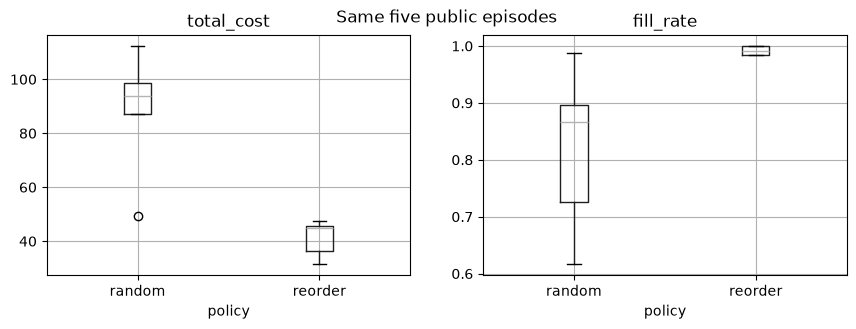

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(10,3.2))
baseline_results.boxplot(column='total_cost',by='policy',ax=axes[0])
baseline_results.boxplot(column='fill_rate',by='policy',ax=axes[1])
fig.suptitle('Same five public episodes'); plt.show()

## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [11]:
# TODO: replace with 4–6 evidence-backed sentences.
interpretation='We can observe that between both strategies, the reorder strategy beats the random strategy.' \
' On average, the reorder strategy costs a lot less than the random strategy (41.16 vs 88.20), fill rate is way higher (99% vs 81%) and unmet demande is 1 vs 14. ' \
'On each 5 seeds, the reorder strategy is better. Eventho the random strategy can have good fill_rate (seed 37), the performance is lower than the reorder strategy and the cost is way higher. ' \
'However, it does not prove that the reorder strategy would work on a real ATM, or that the method is an optimal solution.' \
' Operationnaly, the bank could keep this strategy as a fallback of a reinforcement strategy that should put in place.' \
' All this strategy depends on knowing is the regime is high or low, which we maybe can be wrong on or can change extermely in a day, because of an event or watever.'
print(interpretation or 'Interpretation pending.')

We can observe that between both strategies, the reorder strategy beats the random strategy. On average, the reorder strategy costs a lot less than the random strategy (41.16 vs 88.20), fill rate is way higher (99% vs 81%) and unmet demande is 1 vs 14. On each 5 seeds, the reorder strategy is better. Eventho the random strategy can have good fill_rate (seed 37), the performance is lower than the reorder strategy and the cost is way higher. However, it does not prove that the reorder strategy would work on a real ATM, or that the method is an optimal solution. Operationnaly, the bank could keep this strategy as a fallback of a reinforcement strategy that should put in place. All this strategy depends on knowing is the regime is high or low, which we maybe can be wrong on or can change extermely in a day, because of an event or watever.


## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.